In [45]:
## Python Stuff
import os
import sys
import numpy as np
from array import array
import copy
import time
import matplotlib.pyplot as plt
import matplotlib

os.environ.get("ROOTSYS")

""" run with:
jupyter lab --no-browser --log-level=ERROR --NotebookApp.open_browser=False --NotebookApp.allow_origin='*' --NotebookApp.ip='0.0.0.0'
in terminal
copy the address given into the kernel selection in vs code

or run directly in jupyter lab with the open notebook command
"""

" run with:\njupyter lab --no-browser --log-level=ERROR --NotebookApp.open_browser=False --NotebookApp.allow_origin='*' --NotebookApp.ip='0.0.0.0'\nin terminal\ncopy the address given into the kernel selection in vs code\n\nor run directly in jupyter lab with the open notebook command\n"

In [29]:
## ROOT stuff
import ROOT
from ROOT import TFile, TTree, TCanvas
from ROOT import TH1F, TH2F
import ctypes
import copy

ROOT.gStyle.SetCanvasDefW(600)
ROOT.gStyle.SetCanvasDefH(500)

# ROOT.gErrorIgnoreLevel = ROOT.kFatal
ROOT.gROOT.SetBatch(False)
# ROOT.enableJSVis()
# ROOT.disableJSVis()

In [30]:
sys.path.append(os.environ.get("CF4HOME")+"/code1Analysis/")
print(sys.path)

## Atown's stuff
from helpers.anaStructs import * # includes SORTING class/namespace
from helpers.getSPE import *
import helpers.graphBuilders as GB

['/Users/austindestcroix', '/Users/austindestcroix/packages/root_py311_v6_26.10/myInstall_p311/lib', '/Library/Frameworks/Python.framework/Versions/3.11/lib/python311.zip', '/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11', '/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/lib-dynload', '', '/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages', '/Users/austindestcroix/Desktop/school_holders/projects/sbc/CF4/code1Analysis/', '/Users/austindestcroix/Desktop/school_holders/projects/sbc/CF4/code1Analysis/', '/Users/austindestcroix/Desktop/school_holders/projects/sbc/CF4/code1Analysis/']


Warning in <TCanvas::Constructor>: Deleting canvas with same name: kljlkj


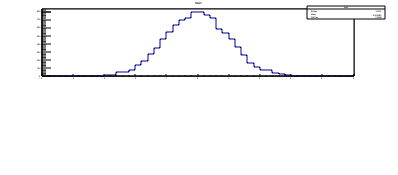

In [31]:
canvas = ROOT.TCanvas("kljlkj", "", 400, 200)
htest = TH1F("htest", "htest", 200, -5, 5)
htest.FillRandom("gaus", 10000)

canvas.Divide(1, 2)
canvas.cd(1)

htest.Rebin(4)

htest.Draw("hist")

canvas.Update()


# # Show the canvas
canvas.Draw()

In [32]:

## ------------- User Inputs ------------- ##
## USER INPUTS (kinda bad ngl) ##
NCHAN = 3
VERBOSE = False
ASK_MATPLOT = True
DO2D = False

# QVAR_USE = "qRCFlat"
# QVAR_USE = "qRCFixed"
QVAR_USE = "qFlat"
# QVAR_USE = "qFixed"
PECUTVALUE = 0.0

## Paths to files, runLists
defPath = str(os.environ["CF4HOME"])+"/procData/" # where to get everything
bkgRunPath = "runLists/analysis1/bkgLists/"       # bkg run list files

In [33]:
## -------- physics and bkg runs -------- ##
runID_cs_bare_heights = [202203101341, 202203101306, 202203101150, 202203101534, 202203101506]
cs_bare_heights = [26.5, 28,	30.5,	32,	34.5]

runID_cs_LP_heights = [202204111600,	202204111454,	202204111423, 202204121321]
cs_LP_heights = [26, 28.5,	30.5, 32]

physicsList = runID_cs_bare_heights + runID_cs_LP_heights

# bkg runs
bkgList_0310 = np.loadtxt(defPath + bkgRunPath+ "date_0310-48V.txt", dtype=int).tolist()
bkgList_0411 = np.loadtxt(defPath + bkgRunPath+ "date_0411-48V.txt", dtype=int).tolist()

# final inputs into code
allBkgs = bkgList_0310 + bkgList_0411
allRuns = allBkgs + physicsList

In [34]:
## Get all RC objects ##
rcList = [] ## everything from here
fList = []

speList = []
chi2list = []

# loading data and SPE analysis
# everything is in rcList
for run in allRuns:
  fpath = defPath + "analysis1/npv1_" + str(run) + ".root"
  f = ROOT.TFile(fpath, "READ") #file opens
  fList.append(f) # NEED THIS to keep ttrees persistent (all reference in Python)

  tt = f.Get("tt")
  rcObj = RunClass(run, tt, fname = fpath)

  rcObj.assign_height(runID_cs_bare_heights, cs_bare_heights)
  rcObj.assign_height(runID_cs_LP_heights, cs_LP_heights)

  rcObj.computeSPE(width = 15, verbose=VERBOSE, varname=QVAR_USE, channels = [i for i in range(NCHAN)], nbins = 150)
  
  rcObj.UprootConstructor()
  rcList.append(rcObj)

  for chan in rcObj.mChannels:
    # print(chan.mSpe.chi2)
    speList.append(chan.mSpe.spe)
    chi2list.append(chan.mSpe.chi2)

Warning in <TSpectrum::SearchHighRes>: Peak buffer full
Warning in <TSpectrum::SearchHighRes>: Peak buffer full
Warning in <TSpectrum::SearchHighRes>: Peak buffer full
Warning in <TSpectrum::SearchHighRes>: Peak buffer full
Warning in <TSpectrum::SearchHighRes>: Peak buffer full
Warning in <TSpectrum::SearchHighRes>: Peak buffer full
Warning in <TSpectrum::SearchHighRes>: Peak buffer full
Warning in <TSpectrum::SearchHighRes>: Peak buffer full
Warning in <TSpectrum::SearchHighRes>: Peak buffer full
Warning in <TSpectrum::SearchHighRes>: Peak buffer full
Warning in <TSpectrum::SearchHighRes>: Peak buffer full
Warning in <TSpectrum::SearchHighRes>: Peak buffer full
Warning in <TSpectrum::SearchHighRes>: Peak buffer full
Warning in <TSpectrum::SearchHighRes>: Peak buffer full
Warning in <TSpectrum::SearchHighRes>: Peak buffer full
Warning in <TSpectrum::SearchHighRes>: Peak buffer full
Warning in <TSpectrum::SearchHighRes>: Peak buffer full
Warning in <TSpectrum::SearchHighRes>: Peak buff

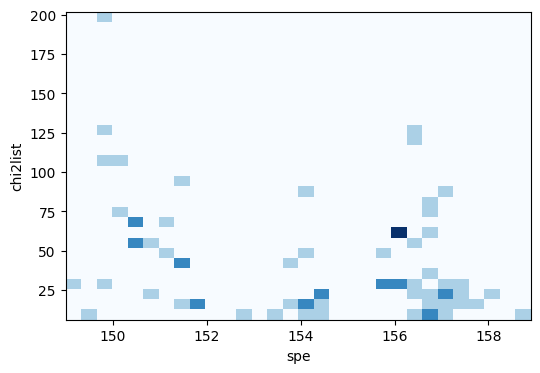

In [35]:
## checking spe and chi2 values
plt.figure(figsize=(6, 4))
plt.hist2d(speList, chi2list, bins=30, cmap='Blues')
plt.xlabel("spe")
plt.ylabel("chi2list")
plt.show()

In [36]:
# printing information
# rcList[0].tt.Show(0)
# for rc in rcList:
#   rc.print()

#### Sorting RC objects ####
rcl_Bkg_0310 = SORTING.pickListOfRC(bkgList_0310, rcList) # get all RC background objects
rcl_cs_bare_heights = SORTING.pickListOfRC(runID_cs_bare_heights, rcList)

rcl_Bkg_0411 = SORTING.pickListOfRC(bkgList_0411, rcList) # get all RC background objects
rcl_cs_lp_heights = SORTING.pickListOfRC(runID_cs_LP_heights, rcList)

######## Building Full Spectra ########
binHigh = 80.
Nbins = 400.
binWidth = (binHigh - 0.) / Nbins
hReference = TH1F("hReference", "hReference", int(Nbins), 0., binHigh) # histogram that everything is built off
hReference.Sumw2(True)

# building all SPE spectra
for rc in rcList:
  rc.BuildSpectrum(hReference, QVAR_USE, PECUTVALUE, rate = True)

# building averaged bkg spectra
hNPE_bkg_0310 = hReference.Clone("hNPE_bkg_0310") # histogram
GB.build_bkgHistogramFast(rcl_Bkg_0310, QVAR_USE, hNPE_bkg_0310, PECUTVALUE) # this calls build_SPEFixedHistogram iteratively, does rate calculation...

hNPE_bkg_0411 = hReference.Clone("hNPE_bkg_0411") # histogram
GB.build_bkgHistogramFast(rcl_Bkg_0411, QVAR_USE, hNPE_bkg_0411, PECUTVALUE) # this calls build_SPEFixedHistogram iteratively, does rate calculation...

## Time between events for one run
hTimeBetweenEvents = TH1F("hTimeBetweenEvents", "hTimeBetweenEvents", 100, 0., 0.2)
for rc in rcl_Bkg_0310:
  rc.BuildTTNE(hTimeBetweenEvents)
  
# for rc in rcl_cs_bare_heights:
#   rc.BuildCorrSpectrum(hNPE_bkg_0310)

# for rc in rcl_cs_lp_heights:
#   rc.BuildCorrSpectrum(hNPE_bkg_0411)

done filling histogram: hNPE_202203101136
done filling histogram: hNPE_202203101245
done filling histogram: hNPE_202203101333
done filling histogram: hNPE_202203101424
done filling histogram: hNPE_202203101457
done filling histogram: hNPE_202203101526
done filling histogram: hNPE_202203101553
done filling histogram: hNPE_202204111213
done filling histogram: hNPE_202204111229
done filling histogram: hNPE_202204111247
done filling histogram: hNPE_202204111323
done filling histogram: hNPE_202204111434
done filling histogram: hNPE_202204111520
done filling histogram: hNPE_202204111623
done filling histogram: hNPE_202203101341
done filling histogram: hNPE_202203101306
done filling histogram: hNPE_202203101150
done filling histogram: hNPE_202203101534
done filling histogram: hNPE_202203101506
done filling histogram: hNPE_202204111600
done filling histogram: hNPE_202204111454
done filling histogram: hNPE_202204111423
done filling histogram: hNPE_202204121321
done building fast bkg histogram f

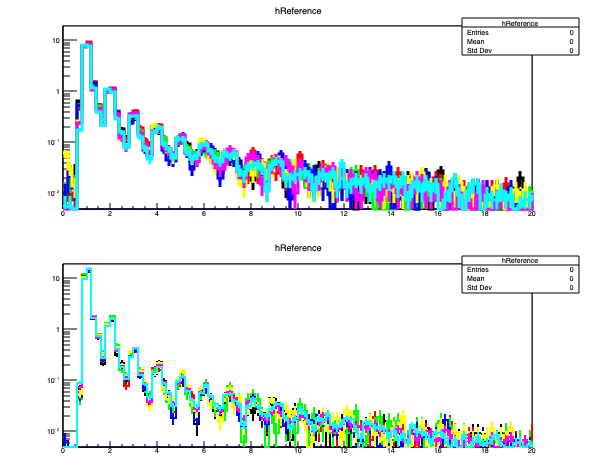

In [37]:
## plotting reference (bkg) figures 
c0 = TCanvas()
c0.Divide(1, 2)
c0.cd(1)
c0.cd(1).SetLogy()

hReference.GetXaxis().SetRangeUser(0, 20)
hReference.Draw("hist")

for rc in rcl_Bkg_0310:
  h = rc.GetSpectrum()
  h.SetLineColor(rcl_Bkg_0310.index(rc)+1)
  h.SetLineWidth(3)

  h.Draw("hist same E")

c0.cd(2)
c0.cd(2).SetLogy()
hReference.Draw("hist")
for rc in rcl_Bkg_0411:
  h = rc.GetSpectrum()
  h.SetLineColor(rcl_Bkg_0411.index(rc)+1)
  h.SetLineWidth(2)

  h.Draw("hist same E")

c0.Update()
c0.Draw()


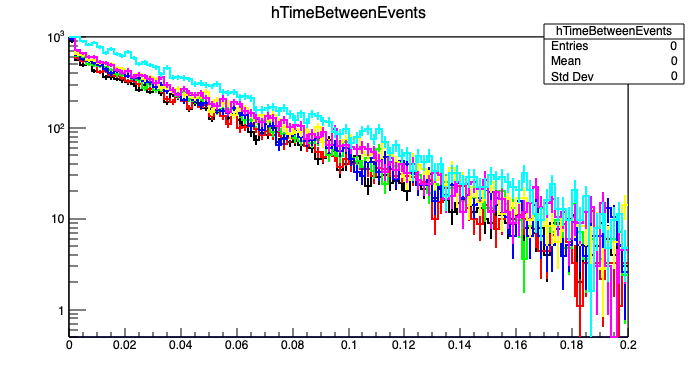

In [38]:
#### TTNE figs ####
c2 = TCanvas("", "", 700, 400)
# hTimeBetweenEvents.GetXaxis().SetLimits(0.1, 1000)
hTimeBetweenEvents.SetMaximum(1000)
hTimeBetweenEvents.Draw("hist")

for rc in rcl_Bkg_0310:
  h = rc.mhTTNE
  index = rcl_Bkg_0310.index(rc)
  h.SetLineColor(index+1)
  h.SetLineWidth(2)
  h.Scale(1+index/10.)
  h.Draw("hist same E")

c2.SetLogy()
c2.Update()
c2.Draw()

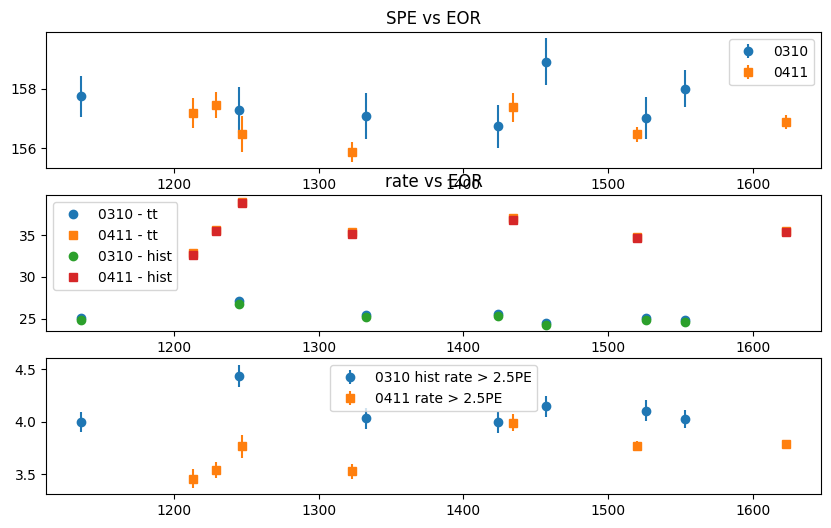

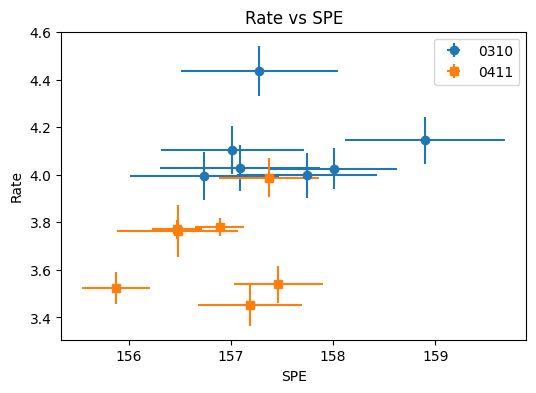

In [39]:
################ Matplotlib Math ################
### Bkg investigation ###

## SPE size ##
plotChan = 2
ySPE_0310 = np.array([rc.GetSPE(plotChan) for rc in rcl_Bkg_0310])
yeSPE_0310 = np.array([rc.GetChan(plotChan).mSpe.espe for rc in rcl_Bkg_0310])
xEOR_0310 = np.array([int(rc.GetEORtime()) for rc in rcl_Bkg_0310])

ySPE_0411 = np.array([rc.GetSPE(plotChan) for rc in rcl_Bkg_0411])
yeSPE_0411 = np.array([rc.GetChan(plotChan).mSpe.espe for rc in rcl_Bkg_0411])
xEOR_0411 = np.array([int(rc.GetEORtime()) for rc in rcl_Bkg_0411])

## TT rate ##
yTTrate_0310 = np.array([rc.GetRate() for rc in rcl_Bkg_0310])
yeTTrate_0310 = np.array([rc.mRateError for rc in rcl_Bkg_0310])

yTTrate_0411 = np.array([rc.GetRate() for rc in rcl_Bkg_0411])
yeTTrate_0411 = np.array([rc.mRateError for rc in rcl_Bkg_0411])

## histogram full rate ##
yHistRate_0310 = np.array([rc.GetSpectrum().Integral() for rc in rcl_Bkg_0310])
yHistRate_0411 = np.array([rc.GetSpectrum().Integral() for rc in rcl_Bkg_0411])

## 2PE and above rates ##
lowPE = 2.5
ey = ctypes.c_double()
yHistRate2_0310 = []
for rc in rcl_Bkg_0310:
  integ = rc.GetSpectrum().IntegralAndError(int(lowPE/binWidth), int(20./binWidth), ey)
  yHistRate2_0310.append([integ, copy.copy((float(ey.value)))])
yHistRate2_0310 = np.array(yHistRate2_0310)

yHistRate2_0411 = []
for rc in rcl_Bkg_0411:
  integ = rc.GetSpectrum().IntegralAndError(int(lowPE/binWidth), int(20./binWidth), ey)
  yHistRate2_0411.append([integ, copy.copy((float(ey.value)))])
yHistRate2_0411 = np.array(yHistRate2_0411)

# yHistRate2_0310 = np.array([rc.GetSpectrum().Integral(int(2.5/binWidth), int(20./binWidth)) for rc in rcl_Bkg_0310])
# yHistRate2_0411 = np.array([rc.GetSpectrum().Integral(int(2.5/binWidth), int(20./binWidth)) for rc in rcl_Bkg_0411])

##### Rate, SPE vs EOR #####
plt.ion()
bkgfig, bkgaxes = plt.subplots(3, 1, figsize = (10, 6))

bkgaxes[0].errorbar(x = xEOR_0310, y = ySPE_0310, yerr = yeSPE_0310, label = "0310", marker = "o", linestyle = 'None')
bkgaxes[0].errorbar(x = xEOR_0411, y = ySPE_0411, yerr = yeSPE_0411, label = "0411", marker = "s", linestyle = 'None')

bkgaxes[0].set_title("SPE vs EOR")
bkgaxes[0].legend()

bkgaxes[1].plot(xEOR_0310, yTTrate_0310, marker = "o", linestyle = 'None', label = "0310 - tt")
bkgaxes[1].plot(xEOR_0411, yTTrate_0411, marker = "s", linestyle = 'None', label = "0411 - tt")

bkgaxes[1].plot(xEOR_0310, yHistRate_0310, marker = "o", linestyle = 'None', label = "0310 - hist")
bkgaxes[1].plot(xEOR_0411, yHistRate_0411, marker = "s", linestyle = 'None', label = "0411 - hist")

bkgaxes[1].set_title("rate vs EOR")
bkgaxes[1].legend()

bkgaxes[2].errorbar(xEOR_0310, yHistRate2_0310[:,0], yerr = yHistRate2_0310[:, 1], marker = "o", linestyle = 'None', label="0310 hist rate > 2.5PE")
bkgaxes[2].errorbar(xEOR_0411, yHistRate2_0411[:,0], yerr = yHistRate2_0411[:,1], marker = "s", linestyle = 'None', label="0411 rate > 2.5PE")
bkgaxes[2].legend()

##### SPE vs Rate plots #####
fig, ax = plt.subplots(1, 1, figsize=(6, 4))

ax.errorbar(x = ySPE_0310, y = yHistRate2_0310[:, 0], xerr = yeSPE_0310, yerr = yHistRate2_0310[:, 1], marker = "o", linestyle = 'None', label = "0310")
ax.errorbar(x = ySPE_0411, y = yHistRate2_0411[:,0], xerr = yeSPE_0411, yerr = yHistRate2_0411[:,1], marker = "s", linestyle = 'None', label = "0411")

ax.legend()
ax.set_xlabel("SPE")
ax.set_ylabel("Rate")
ax.set_title("Rate vs SPE")

plt.show()


In [40]:
## Get and build the bkg corrected spectra
for rc in rcl_cs_bare_heights:
  rc.FindClosestRC(rcl_Bkg_0310)
  rc.BuildCorrSpectrum()

for rc in rcl_cs_lp_heights:
  rc.FindClosestRC(rcl_Bkg_0411)
  rc.BuildCorrSpectrum()

In [41]:
# 2d figures
if DO2D:
  h2sharing = TH2F("h2sharing", "h2sharing", int(80), 0., binHigh, int(40), 0., 1.0)
  for rc in rcl_cs_bare_heights+rcl_Bkg_0310[1:2]:
    hthis = h2sharing.Clone("h2sharing_" + str(rc.id))
    hthis.SetTitle("h2sharing_" + str(rc.GetHeight()))
    GB.build_2d_foccupancyHistogram(rc, hthis, qvar = QVAR_USE)
    rc.mh2d = hthis

cduh = []
if DO2D:
  for rc in rcl_cs_bare_heights+rcl_Bkg_0310[1:2]:
    c = TCanvas()
    cduh.append(c)
    c.cd()
    rc.mh2d.Draw("colz")
    c.SetLogz()
    c.Update()

Warning in <TCanvas::Constructor>: Deleting canvas with same name: canvas10


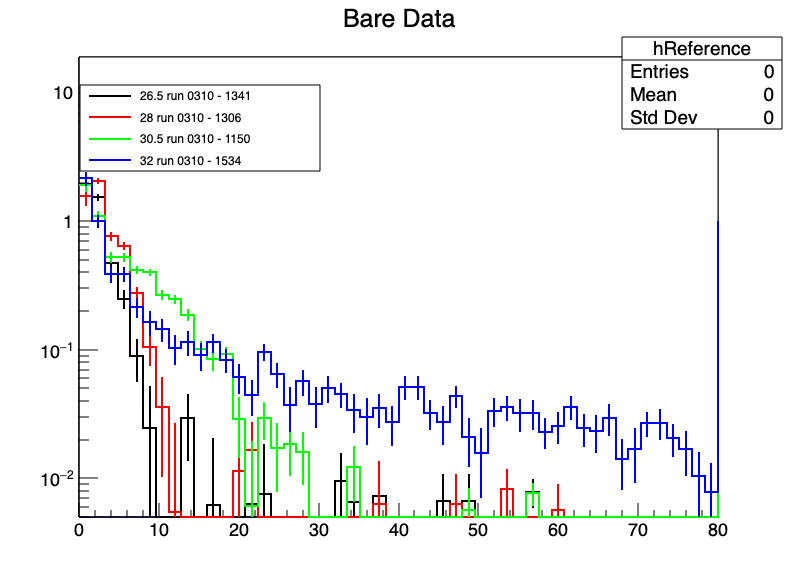

In [42]:
#### Corrected Spectra ####
heightSkip = [34.5]

## Bare Data ##
c1 = TCanvas("canvas10", "Histogram Canvas", 800, 600)
hReference.SetTitle("Bare Data")
hReference.GetXaxis().SetRangeUser(0, 80)
hReference.Draw("hist")

leg1 = ROOT.TLegend()

for rc in rcl_cs_bare_heights:
  if rc.GetHeight() in heightSkip:
    continue
  h = rc.GetCorrSpectrum()
  h.Rebin(8)
  h.SetLineColor(rcl_cs_bare_heights.index(rc)+1)
  h.SetLineWidth(2)
  leg1.AddEntry(h, str(rc.mHeight) + " run " + rc.mDate + " - " + rc.GetEORtime(), "L")
  h.Draw("hist same E")

leg1.Draw("same")

c1.SetLogy()
c1.Update()
c1.Draw()

## LP data ##
c2 = TCanvas()
hReference.SetTitle("Longpass Data")
hReference.Draw("hist")
leg2 = ROOT.TLegend()

for rc in rcl_cs_lp_heights:
  if rc.GetHeight() in heightSkip:
    continue
  h = rc.GetCorrSpectrum()
  h.Rebin(8)
  h.SetLineColor(rcl_cs_lp_heights.index(rc)+1)
  h.SetLineWidth(2)
  leg2.AddEntry(h, str(rc.mHeight) + " run " + rc.mDate + " - " + rc.GetEORtime(), "L")
  h.Draw("hist same E")


26
28.5
30.5
32


Warning in <TCanvas::Constructor>: Deleting canvas with same name: LP vs Bare


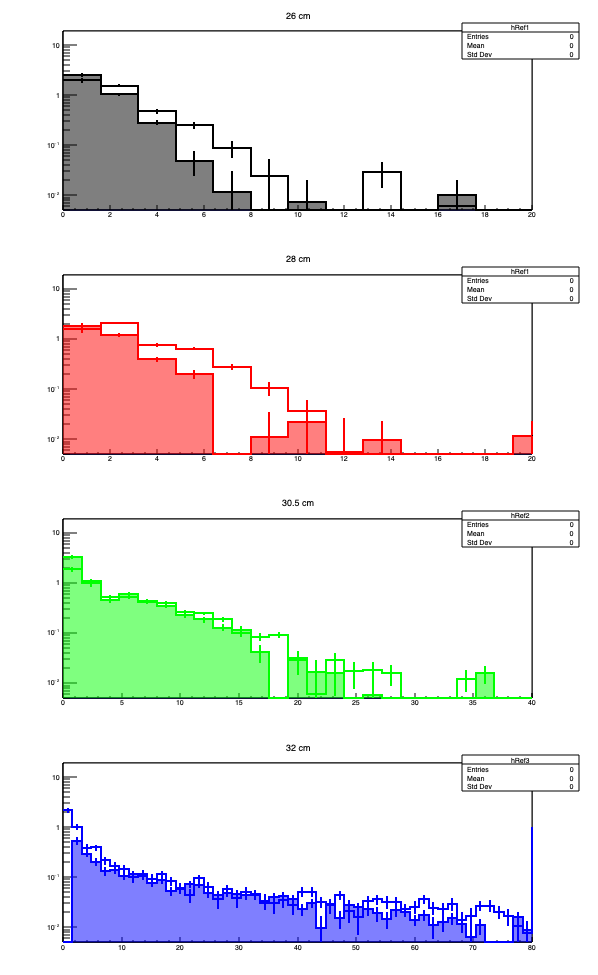

In [43]:
FindRCbyHeight = lambda h, rclist: next((rc for rc in rclist if rc.GetHeight() == h), None)
## Focusing on the 28cm, 30.5, 32cm one, it's background run and their bkg runs
# rc32Bare = FindRCbyHeight(32, rcl_cs_bare_heights)
 
## LP and Bare overlays ##
c3 = TCanvas("LP vs Bare", "LP vs Bare", 600, 1000)
c3.Divide(1, 4)
# leg3 = ROOT.TLegend()

## 26cm ##
c3.cd(1).SetLogy()
hRef0 = hReference.Clone("hRef1")
hRef0.SetTitle("26 cm")
hRef0.GetXaxis().SetRangeUser(0, 20)
hRef0.Draw("hist")

rcBare = FindRCbyHeight(26.5, rcl_cs_bare_heights)
rcBare.GetCorrSpectrum().Draw("hist same E")
# type(rcBare)

rcLP = FindRCbyHeight(26, rcl_cs_lp_heights)
rcLP.GetCorrSpectrum().SetFillColorAlpha(rcLP.GetCorrSpectrum().GetLineColor(), 0.5)
rcLP.GetCorrSpectrum().Draw("hist same E")

## 28.5cm ##
c3.cd(2).SetLogy()
hRef1 = hReference.Clone("hRef1")
hRef1.SetTitle("28 cm")
hRef1.GetXaxis().SetRangeUser(0, 20)
hRef1.Draw("hist")

rcBare = FindRCbyHeight(28, rcl_cs_bare_heights)
rcBare.GetCorrSpectrum().Draw("hist same E")
type(rcBare)

rcLP = FindRCbyHeight(28.5, rcl_cs_lp_heights)
rcLP.GetCorrSpectrum().SetFillColorAlpha(rcLP.GetCorrSpectrum().GetLineColor(), 0.5)
rcLP.GetCorrSpectrum().Draw("hist same E")

## 30.5cm ##
c3.cd(3).SetLogy()
hRef2 = hReference.Clone("hRef2")
hRef2.SetTitle("30.5 cm")
hRef2.GetXaxis().SetRangeUser(0, 40)
hRef2.Draw("hist")

rcBare = FindRCbyHeight(30.5, rcl_cs_bare_heights)
rcBare.GetCorrSpectrum().Draw("hist same E")

rcLP = FindRCbyHeight(30.5, rcl_cs_lp_heights)
rcLP.GetCorrSpectrum().SetFillColorAlpha(rcLP.GetCorrSpectrum().GetLineColor(), 0.5)
rcLP.GetCorrSpectrum().Draw("hist same E")

## 32cm ##
c3.cd(4).SetLogy()
hRef3 = hReference.Clone("hRef3")
hRef3.SetTitle("32 cm")
# hRef3.GetXaxis().SetRange()
hRef3.Draw("hist")

rcBare = FindRCbyHeight(32, rcl_cs_bare_heights)
rcBare.GetCorrSpectrum().Draw("hist same E")

for r in rcl_cs_lp_heights:
  print(r.mHeight)

rcLP = FindRCbyHeight(32, rcl_cs_lp_heights)
rcLP.GetCorrSpectrum().SetFillColorAlpha(rcLP.GetCorrSpectrum().GetLineColor(), 0.5)
rcLP.GetCorrSpectrum().Draw("hist same E")

c3.Update()
c3.Draw()

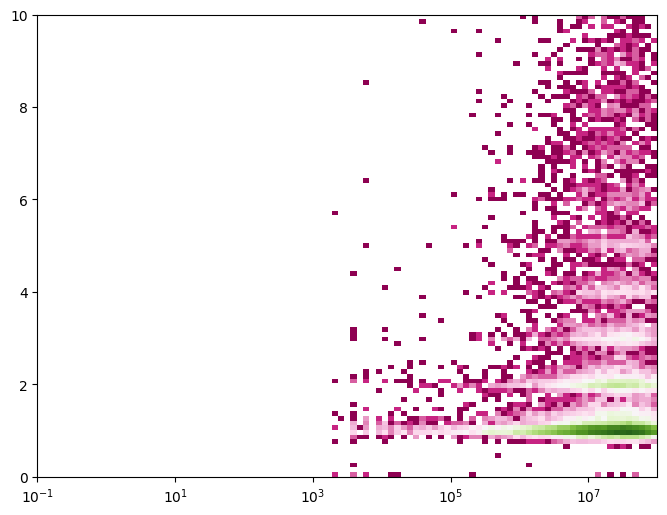

In [48]:
rc32 = FindRCbyHeight(32, rcl_cs_bare_heights)
rc32.GetHeight()


rc32.BuildCorrectEventTimes()
timePulses, NPElist = rc32.BuildCorrectEventPulseTimes(QVAR_USE, peCut=0.5)

ttnp = (timePulses[1:] - timePulses[:-1]) # currently in ns
NPElist2 = NPElist[1:]

x_edges = np.logspace(-1, 8, num = 100)
y_edges = np.linspace(0, 10, num = 100)
# plt.hist(evTime, bins = 500, range = (0, int(max(evTime))), histtype="step")
# plt.hist(evTimeFixed, bins = 500, range = (0, max(evTimeFixed)))
# plt.plot()
# plt.hist(ttnp, bins = 100)
fig, ax = plt.subplots(1, 1, figsize =(8, 6))
ax.hist2d(ttnp, NPElist2, bins = [x_edges, y_edges], cmap = "PiYG", norm = matplotlib.colors.LogNorm())
# plt.hist2d(NPElist[:-1], NPElist[1:], bins = (100, 100), range=((0, 10), (0, 10)), cmap = "PiYG", norm = matplotlib.colors.LogNorm())
# ax.set_xlim(1, 10**6)
ax.set_xscale("log")

plt.show()
